<a href="https://colab.research.google.com/github/Shxrp08/Project_SG_I-Smile_Group6_2026/blob/main/Project_SG_Group_6_Rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ML Regression Model

### Library yg Hrs Dipanggil:

In [1]:
# Manipulasi Data dan Visual

import pandas as pd                                                              #Baca file CSV, ngolah isi data tabel, cari missing value
import numpy as np                                                               #Operasi matrix n array
import matplotlib.pyplot as plt                                                  #bikin tampilan gambar bewarna
import seaborn as sns                                                            #grafik warna-warni (penyempurna matplotlib)

#Pre-processing dan pemisahan data

from sklearn.model_selection import (
    train_test_split,                                                            # rasio train dan test; text_size=0.XX untuk skala 100-XX : XX
    cross_val_score                                                              # bagi data latih: cv=X, model dilatih X kali dr semua data latih yg dibagi X
)
from sklearn.preprocessing import (
    StandardScaler,                                                              # Feature scaling: standarisasi
    MinMaxScaler,                                                                # Feature scaling: normalisasi
    OneHotEncoder,                                                               # text kategori nominal (gada tingkatan) jadi kolom biner 0/1
    OrdinalEncoder                                                               # kategori tingkatan jadi 0,1,2,3,...
)
from sklearn.compose import ColumnTransformer                                    #gabung teknik olah data berbeda (scaling, encoding), dlm satu alur
from sklearn.pipeline import Pipeline                                            #bungkus ColumnTransformer dan model ML jadi 1 paket biar gada data leakage

#Algoritma model regresi

from sklearn.neighbors import KNeighborsRegressor                                #KNN (regresi)
from sklearn.ensemble import RandomForestRegressor                               #Random Forest (regresi)
from sklearn.linear_model import LinearRegression                                #Linear Regression
from sklearn.tree import DecisionTreeRegressor                                   #Decision Tree (regresi)

#metrik evaluasi regresi

from sklearn.metrics import (
    mean_squared_error,                                                          # MSE
    mean_absolute_error,                                                         # MAE
    r2_score                                                                     # R^2
)


                                                    
### Memasukkan dataset yang mau digunakan (sebagai Data Path)

In [3]:
#DATA_PATH
DATA_PATH = "/content/ai_student_impact_dataset (1)-selected-columns.csv"        #Path dari dataset yang akan digunakan

 #  df = data frame, pd = pandas
df = pd.read_csv(DATA_PATH)                                                      # Membaca data
print("Ukuran data (baris, kolom):", df.shape)                                   # df.shape: menunjukkan berapa banyak baris dan kolom pada csv
df.head(15) #default = 5                                                         # Menampilkan berapa banyak indeks data yang akan ditampilkan pada kolom

Ukuran data (baris, kolom): (50000, 10)


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55
5,100006,STEM,Junior,3.449,6.50,Debugging/Troubleshooting,Beginner,1,False,14.19
6,100007,STEM,Freshman,3.622,31.41,Summarizing_Reading,Advanced,5,True,13.11
7,100008,Arts,Junior,2.746,5.33,Copywriting/Drafting,Intermediate,3,False,18.45
8,100009,Business,Sophomore,3.420,2.00,Debugging/Troubleshooting,Beginner,2,True,2.87
9,100010,Business,Sophomore,3.046,19.99,Debugging/Troubleshooting,Intermediate,2,True,12.49



### Menampilkan tipe data dan jumlah nilai non-null (nilai tidak kosong)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Student_ID                50000 non-null  int64  
 1   Major_Category            50000 non-null  object 
 2   Year_of_Study             50000 non-null  object 
 3   Pre_Semester_GPA          50000 non-null  float64
 4   Weekly_GenAI_Hours        50000 non-null  float64
 5   Primary_Use_Case          50000 non-null  object 
 6   Prompt_Engineering_Skill  50000 non-null  object 
 7   Tool_Diversity            50000 non-null  int64  
 8   Paid_Subscription         50000 non-null  bool   
 9   Traditional_Study_Hours   50000 non-null  float64
dtypes: bool(1), float64(3), int64(2), object(4)
memory usage: 3.5+ MB


####______________________________________
## EDA (Exploratory Data Analysis)
####______________________________________

###1. Analisis Satu Variabel (value_counts)

In [5]:
# Kita bisa memakai fungsi value_counts untuk menghitung jumlah baris data (frekuensi) untuk setiap kategori

# misal, kita ambil dua kategori: Major_Category dan Year_of_Study

display(df["Major_Category"].value_counts())
display(df["Year_of_Study"].value_counts())

# kalau gk pake fungsi display dan menulis kedua panggilan dengan

#df["Year_of_Study"].value_counts()
#df["Major_Category"].value_counts()

#ipynb cuma bakal jalanin perintah terbawah!

,count
Major_Category,
STEM,15059
Business,12538
Humanities,9994
Medical,6476
Arts,5933


,count
Year_of_Study,
Junior,11045
Freshman,11031
Senior,10634
Sophomore,9860
Graduate,7430


In [14]:
# value_counts bisa juga buat tipe data selain kategori. tapi untuk kasus yang mungkin memiliki sangat banyak variasi (kayak float yang detail),
# kita berikan parameter bins untuk memberi batas rentang!

display(df["Pre_Semester_GPA"].value_counts(bins=5).reset_index().rename(columns={"index": "Pre_Semester_GPA", "Pre_Semester_GPA": "Count"}))

display(df["Pre_Semester_GPA"].value_counts(bins=5))

,Pre_Semester_GPA,count
0,"(2.872, 3.435]",20525
1,"(3.435, 3.998]",15907
2,"(2.309, 2.872]",10602
3,"(1.746, 2.309]",2717
4,"(1.179, 1.746]",249


,count
"(2.872, 3.435]",20525
"(3.435, 3.998]",15907
"(2.309, 2.872]",10602
"(1.746, 2.309]",2717
"(1.179, 1.746]",249


In [ ]:
#Versi persentase untuk value_counts

(df["Primary_Use_Case"].value_counts(normalize=True) * 100).round(2)

# Normalize=True digunakan untuk merubah nilai desimal ke persentase
# Round(X) digunkan untuk membulatkan X angka dibelakang koma

,proportion
Primary_Use_Case,
Debugging/Troubleshooting,24.59
Copywriting/Drafting,24.02
Ideation,21.44
Summarizing_Reading,17.27
Direct_Answer_Generation,12.68


###2. Visualisasi

####2a. Membuat Histogram

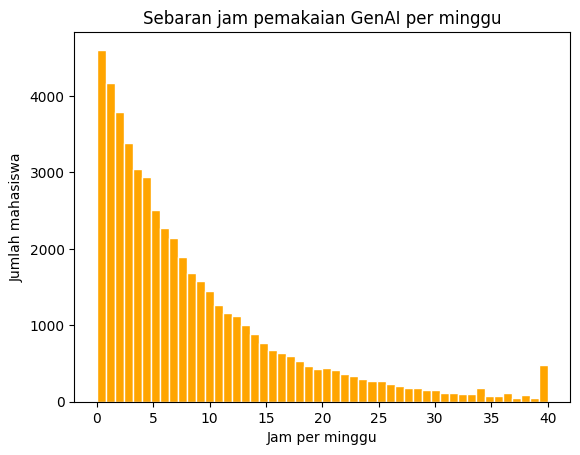

In [ ]:
# Misal, kita membuat histogram terkait distribusi jam pemakaian GenAI per minggu dari informasi pada Weekly_GenAI_Hours yang ada di csv

# plt = pyplot

plt.hist(df["Weekly_GenAI_Hours"], bins=50, color="orange", edgecolor="white")      #plt.hist: membuat grafik histogram
plt.title("Sebaran jam pemakaian GenAI per minggu")                                 #plt.title: membuat judul dari histogram
plt.xlabel("Jam per minggu")                                                        #plt.xlabel: membuat nilai pada sumbu x
plt.ylabel("Jumlah mahasiswa")                                                      #plt.ylabel: membuat nilai pada sumbu y
plt.show()                                                                          #plt.show: menampilkan grafiknya

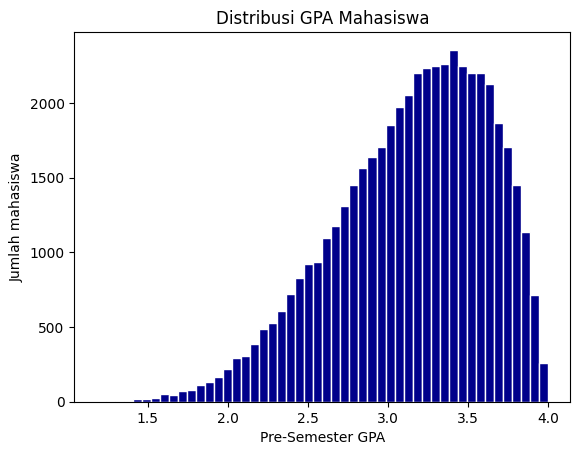

In [ ]:
# Misal, histogram terkait distribusi IPK(GPA) mahasiswa pre-semester yang ada pada tipe data Pre_Semester_GPA

plt.hist(df["Pre_Semester_GPA"], bins=50, color="darkblue", edgecolor="white")  #membuat histogram
plt.title("Distribusi GPA Mahasiswa")                                           #judul histogram
plt.xlabel("Pre-Semester GPA")                                                  #informasi sumbu x
plt.ylabel("Jumlah mahasiswa")                                                  #informasi sumbu y
plt.show()                                                                      #menampilkan histogram

####2b. Conditional Counting: cek baris spesifik

In [ ]:
#Misal, dari histogram sebelumnya, kita mencari berapa banyak mahasiswa dengan GPA X dengan parameter Pre_Semester_GPA

jumlah_mahasiswa_ipk = (df["Pre_Semester_GPA"] >= 3.5).sum()
print("Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5:", jumlah_mahasiswa_ipk)

Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5: 13346


In [ ]:
#Bisa dicari dengan cara lain, seperti berikut:

print("Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5::", (df["Pre_Semester_GPA"] >= 3.5).sum())


Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5:: 13346


####2c. Sebaran/Distribusi

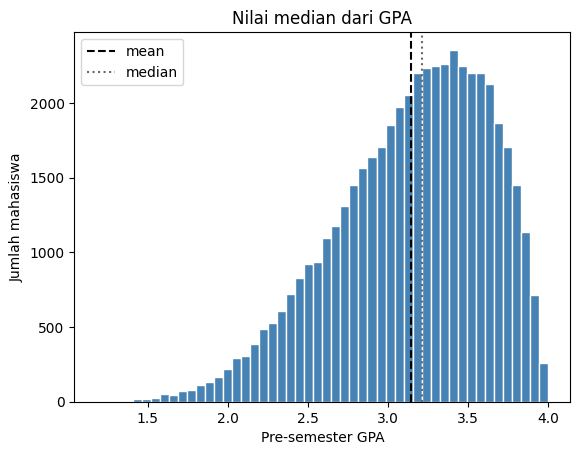

In [ ]:
# Sebaran data

plt.hist(df["Pre_Semester_GPA"], bins=50, color="steelblue", edgecolor="white")
plt.axvline(df["Pre_Semester_GPA"].mean(), color="black", linestyle="--", label="mean") #untuk menunjukan mean (ditunjukkan dengan garis tebal putus putus)
plt.axvline(df["Pre_Semester_GPA"].median(), color="dimgray", linestyle=":", label="median") #untuk menunjukan garis tengah atau nilai median (ditunjukkan dengan garis tipis putus putus)
plt.title("Nilai median dari GPA")
plt.xlabel("Pre-semester GPA")
plt.ylabel("Jumlah mahasiswa")
plt.legend()
plt.show()

####2d. Hubungan GPA Mahasiswa dengan Sebaran jam pemakaian GenAI per minggu

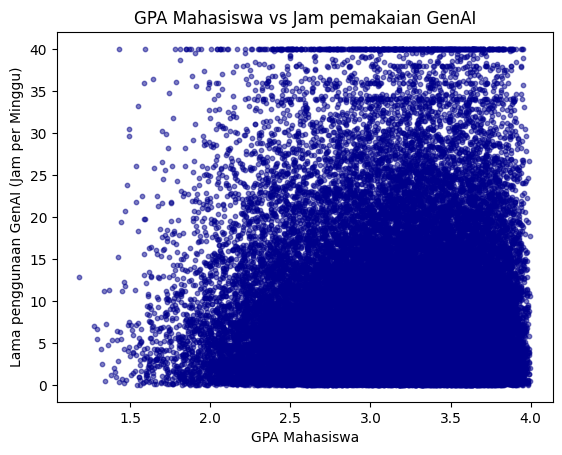

In [ ]:
plt.scatter(df["Pre_Semester_GPA"], df["Weekly_GenAI_Hours"], alpha=0.5, s=10, color="darkblue")  # Menampilkan nilai  dua data
plt.title("GPA Mahasiswa vs Jam pemakaian GenAI")
plt.xlabel("GPA Mahasiswa")
plt.ylabel("Lama penggunaan GenAI (Jam per Minggu)")
plt.show()

####2e. Boxplot

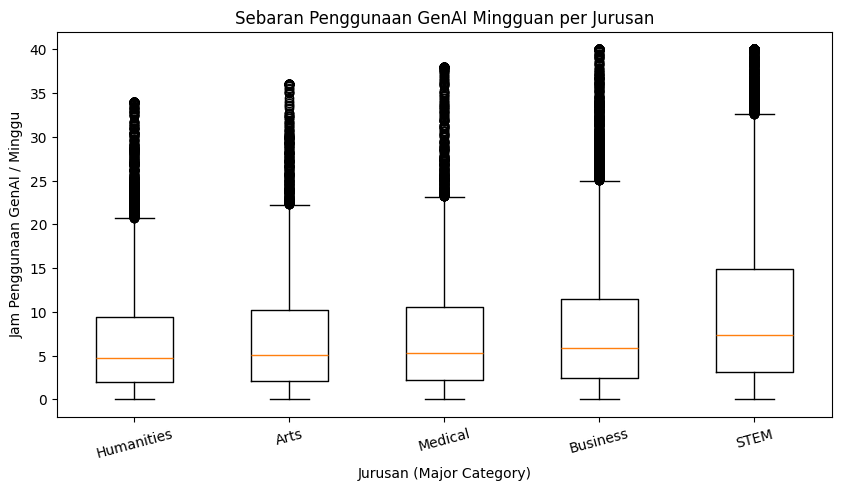

,Weekly_GenAI_Hours
Major_Category,
Humanities,4.72
Arts,5.07
Medical,5.24
Business,5.82
STEM,7.40


In [ ]:
# Median jam GenAI per jurusan, diurutkan dari yang paling sedikit
median_per_jurusan = df.groupby("Major_Category")["Weekly_GenAI_Hours"].median().sort_values()  #groupby mengelompokkan baris berdasarkan nilai di kolom tertentu
urutan = median_per_jurusan.index
jam_per_jurusan = [df.loc[df["Major_Category"] == k, "Weekly_GenAI_Hours"] for k in urutan]  #sort.values() untuk mengurutkan hasil dari nilai terkecil ke terbesar agar boxplot rapi.

plt.figure(figsize=(10, 5))                                             #untuk membuat "kanvas kosong" dimana diagram akan digambar
plt.boxplot(jam_per_jurusan)                                            #untuk menggambar boxplot (diagram kotak-garis)
plt.xticks(range(1, len(urutan) + 1), urutan, rotation=15)              #untuk mengatur label di sumbu x
#NB: (range(1, len(urutan)+ 1), urutan, rotation=15); range itu selalu diisi 1 karena label boxplot matplotlib dimulai dari 1, urutan adalah teks yang akan ditampilkan, + 1 karena fungsi range(a,b) menghasilkan angka dari a sampai b dikurangi 1
plt.title("Sebaran Penggunaan GenAI Mingguan per Jurusan")              #judul
plt.xlabel("Jurusan (Major Category)")                                  #informasi sumbu x
plt.ylabel("Jam Penggunaan GenAI / Minggu")                             #informasi sumbu y
plt.show()                                                              #menampilkan diagram

median_per_jurusan

####2f. Heatmap, mengukur seberapa kuat dua kolom yg bergerak bersama dalam garis lurus (bernilai -1 hingga 1)  (!!penjelasan kurang!!)

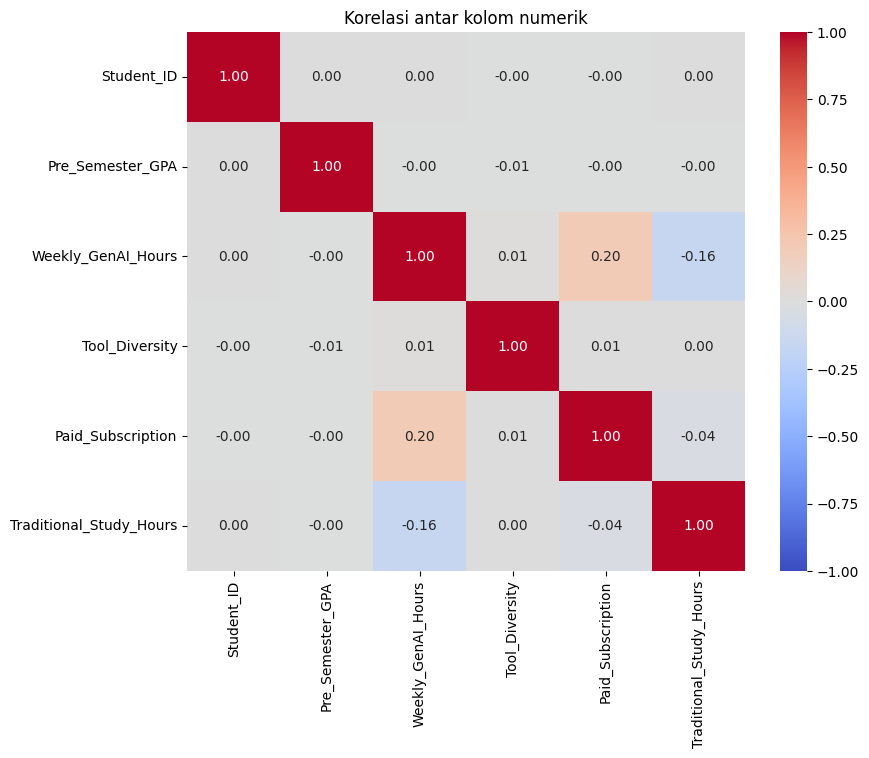

,Weekly_GenAI_Hours
Weekly_GenAI_Hours,1.00
Paid_Subscription,0.20
Tool_Diversity,0.01
Student_ID,0.00
Pre_Semester_GPA,-0.00
Traditional_Study_Hours,-0.16


In [ ]:
korelasi = df.corr(numeric_only=True)                       #membuat korelasi dari DataFrame, numeric_only=True agar hanya menampilkan angka numerik

plt.figure(figsize=(9, 7))                                  #membuat "kanvas kosong" yg akan digunakan utk membuat heatmap
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Korelasi antar kolom numerik")
plt.show()

korelasi["Weekly_GenAI_Hours"].sort_values(ascending=False).round(2)

####_________________________
## Data Pre-Processing
####_________________________

###Data cleaning, menghapus semua salinan


In [ ]:
df_clean = df.copy()                       #membersihkan DataFrame, gunakan df.copy agar hanya menghapus data salinan
print("Ukuran df_clean:", df_clean.shape)  #menampilkan baris dan kolom dari data

Ukuran df_clean: (50000, 10)


###Cari missing_value, kolom yang tidak terdapat data sama sekali dan jumlahnya

In [ ]:
df_clean.isnull().mean()  #isnull() untuk mencari data yg null atau kosong, mean() untuk mencari mean

,0
Student_ID,0.0
Major_Category,0.0
Year_of_Study,0.0
Pre_Semester_GPA,0.0
Weekly_GenAI_Hours,0.0
Primary_Use_Case,0.0
Prompt_Engineering_Skill,0.0
Tool_Diversity,0.0
Paid_Subscription,0.0
Traditional_Study_Hours,0.0


###Karena tidak terdapat missing value (data sudah sangat lengkap sehingga tidak ada yang kosong), maka kita langsung melakukan duplikat agar tidak ada data yang dihitung dua kali

In [ ]:
df_clean.duplicated().sum()       #Membersihkan data duplikat

np.int64(0)

###Contoh data duplikatnya

In [ ]:
contoh_duplikat = df_clean[df_clean.duplicated(keep=False)]                     #keep=False digunakan untuk menandai semua baris asli dan duplikatnya menjadi True
contoh_duplikat.sort_values(["Major_Category", "Pre_Semester_GPA"]).head(6)     #sort_values() untuk mengurutkan baris berdasarkan dua kolom secara berurutan, head(6) untuk menampilkan 6 baris dari hasil

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours


In [ ]:
df_clean = df_clean.drop_duplicates()                             #membuang data duplikat dari df_clean
print("Ukuran setelah duplikat dibuang:", df_clean.shape)         #df_clean.shape untuk menunjukkan baris dan kolom dari DF yang dibersihkan

Ukuran setelah duplikat dibuang: (50000, 10)


###Mengecek outlier, yaitu nilai yang jauh berbeda dari mayoritas data (nilai ekstrim), agar tidak mengganggu model

In [ ]:
df_clean.describe().round(1)  #Menghasilkan ringkasan statistik untuk semua kolom numerik, round(1) untuk membulatkan 1 angka dibelakang koma

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours
count,50000.0,50000.0,50000.0,50000.0,50000.0
mean,125000.5,3.1,8.4,2.8,11.2
std,14433.9,0.5,8.3,1.2,5.2
min,100001.0,1.2,0.0,1.0,1.0
25%,112500.8,2.8,2.4,2.0,7.6
50%,125000.5,3.2,5.8,3.0,11.2
75%,137500.2,3.5,11.7,4.0,14.7
max,150000.0,4.0,40.0,5.0,35.9


###Buat diagram boxplot dari data outlier

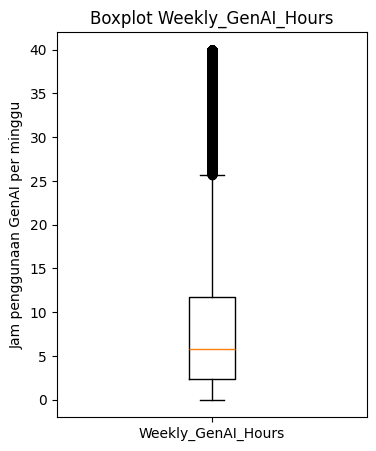

In [ ]:
plt.figure(figsize=(4, 5))                    #Membuat kanvas kosong untuk diagram
plt.boxplot(df_clean["Weekly_GenAI_Hours"])           #Membuat diagram boxplot
plt.title("Boxplot Weekly_GenAI_Hours")               #Untuk judul dari boxplot
plt.ylabel("Jam penggunaan GenAI per minggu")        #Informasi sumbu y
plt.xticks([1], ["Weekly_GenAI_Hours"])               #informasi sumbu x
plt.show()                                    #Menampilkan boxplot

###Gunakan metode IQR untuk membaca boxplot nya

In [ ]:
Q1 = df_clean["Weekly_GenAI_Hours"].quantile(0.25)          #Q1 adalah data yg bernilai 25%
Q3 = df_clean["Weekly_GenAI_Hours"].quantile(0.75)          #Q3 75%
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_genai = df_clean[(df_clean["Weekly_GenAI_Hours"] < batas_bawah) | (df_clean["Weekly_GenAI_Hours"] > batas_atas)]
print(f"Q1 = {Q1:.1f}, Q3 = {Q3:.1f}, IQR = {IQR:.1f}")
print(f"Batas bawah = {batas_bawah:.1f}, batas atas = {batas_atas:.1f}")
print("Jumlah outlier Weekly_GenAI_Hours:", len(outlier_genai))

Q1 = 2.4, Q3 = 11.7, IQR = 9.3
Batas bawah = -11.6, batas atas = 25.7
Jumlah outlier Weekly_GenAI_Hours: 2583


###Sel dibawah ini berfungsi untuk melihat 3 outlier yang paling ekstrem, supaya kamu bisa menilai apakah outlier itu nyata atau salah catat.

In [ ]:
outlier_genai.sort_values("Weekly_GenAI_Hours", ascending=False).head(3)

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours
49937,149938,Business,Freshman,3.113,40.0,Direct_Answer_Generation,Intermediate,2,True,14.87
49338,149339,Business,Junior,3.167,40.0,Ideation,Beginner,3,True,8.66
49296,149297,STEM,Sophomore,3.886,40.0,Copywriting/Drafting,Advanced,3,True,8.01


##Setelah itu lanjut ke encoding

In [ ]:
contoh = df_clean.drop_duplicates(subset="Major_Category")["Major_Category"]
pd.concat([contoh, pd.get_dummies(contoh, dtype=int)], axis=1)

,Major_Category,Arts,Business,Humanities,Medical,STEM
0,Humanities,0,0,1,0,0
1,Medical,0,0,0,1,0
2,Business,0,1,0,0,0
4,STEM,0,0,0,0,1
7,Arts,1,0,0,0,0


In [ ]:
df_final = pd.get_dummies(df_clean, columns=["Major_Category", "Primary_Use_Case"], drop_first=True, dtype=int)
print("Ukuran df_final:", df_final.shape)
df_final.head()

Ukuran df_final: (50000, 16)


,Student_ID,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Major_Category_Business,Major_Category_Humanities,Major_Category_Medical,Major_Category_STEM,Primary_Use_Case_Debugging/Troubleshooting,Primary_Use_Case_Direct_Answer_Generation,Primary_Use_Case_Ideation,Primary_Use_Case_Summarizing_Reading
0,100001,Senior,2.418,23.31,Beginner,1,True,8.13,0,1,0,0,0,0,0,0
1,100002,Junior,3.821,1.12,Advanced,5,False,16.65,0,0,1,0,0,0,1,0
2,100003,Freshman,3.398,21.26,Beginner,2,False,10.35,1,0,0,0,0,0,0,1
3,100004,Senior,3.789,1.82,Intermediate,4,False,15.23,1,0,0,0,0,0,0,0
4,100005,Sophomore,3.635,9.29,Advanced,4,False,12.55,0,0,0,1,1,0,0,0


#Cek hasil akhirnya

In [ ]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Student_ID                                  50000 non-null  int64  
 1   Year_of_Study                               50000 non-null  object 
 2   Pre_Semester_GPA                            50000 non-null  float64
 3   Weekly_GenAI_Hours                          50000 non-null  float64
 4   Prompt_Engineering_Skill                    50000 non-null  object 
 5   Tool_Diversity                              50000 non-null  int64  
 6   Paid_Subscription                           50000 non-null  bool   
 7   Traditional_Study_Hours                     50000 non-null  float64
 8   Major_Category_Business                     50000 non-null  int64  
 9   Major_Category_Humanities                   50000 non-null  int64  
 10  Major_Cate

In [ ]:
print("Ukuran akhir         :", df_final.shape)
print("Total missing        :", df_final.isnull().sum().sum())
print("Total duplikat       :", df_final.duplicated().sum())
print("Kolom yang bukan angka:", df_final.select_dtypes(exclude="number").columns.tolist())

Ukuran akhir         : (50000, 16)
Total missing        : 0
Total duplikat       : 0
Kolom yang bukan angka: ['Year_of_Study', 'Prompt_Engineering_Skill', 'Paid_Subscription']


#Setelah itu, kita masuk ke Regresi Linear untuk memprediksi data

In [ ]:
df_final  #mengecek ulang

,Student_ID,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Major_Category_Business,Major_Category_Humanities,Major_Category_Medical,Major_Category_STEM,Primary_Use_Case_Debugging/Troubleshooting,Primary_Use_Case_Direct_Answer_Generation,Primary_Use_Case_Ideation,Primary_Use_Case_Summarizing_Reading
0,100001,Senior,2.418,23.31,Beginner,1,True,8.13,0,1,0,0,0,0,0,0
1,100002,Junior,3.821,1.12,Advanced,5,False,16.65,0,0,1,0,0,0,1,0
2,100003,Freshman,3.398,21.26,Beginner,2,False,10.35,1,0,0,0,0,0,0,1
3,100004,Senior,3.789,1.82,Intermediate,4,False,15.23,1,0,0,0,0,0,0,0
4,100005,Sophomore,3.635,9.29,Advanced,4,False,12.55,0,0,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,149996,Senior,2.899,12.16,Beginner,2,False,13.36,1,0,0,0,0,0,0,0
49996,149997,Senior,2.870,2.51,Intermediate,1,False,4.67,0,0,0,1,0,0,0,0
49997,149998,Senior,3.177,15.87,Advanced,5,True,3.92,1,0,0,0,0,0,0,1
49998,149999,Junior,3.398,19.91,Intermediate,5,False,7.10,1,0,0,0,1,0,0,0


#Pertama, cari dulu fitur dan target dari dataset yang digunakan

In [ ]:
X = df_final.drop(columns=["Weekly_GenAI_Hours"])       #Membuang kolom yg dipilih (Weekly GenAI Hours) untuk fiturnya
y = df_final["Weekly_GenAI_Hours"]                      #Memakai nilai satu kolom yg dipilih untuk target nya

print("Ukuran X:", X.shape)                             #Menampilkan ukuran kolom dan baris dari X
print("Ukuran y:", y.shape)                             #untuk kolom y nya

Ukuran X: (50000, 15)
Ukuran y: (50000,)


#Setelah mendapatkan fitur dan target, kita uji data nya

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)   #Menggunakan 20% dari dataset untuk data uji, train_test_split untuk "mengacak soal" dari dataset nya, lalu 20% dari hasil acak tsb dibuat menjadi data tes
                                                                                             #random_state tidak berpengaruh pada output atau hasil uji, dia berfungsi untuk sekedar "mengacak urutan soal data uji" nya
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (40000, 15) | X_test: (10000, 15)
y_train: (40000,) | y_test: (10000,)


### Template Tabel:
| A | B | C | D |
|-|-|-|-|
| lapu lapu | argus | zhuxin | kafka |
| | titan collector | pace | hsr |